# Academic Success Prediction: Final Report & Implementation
**Mata Kuliah**: Machine Learning | **Dosen Pengampu**: Ach. Khozaimi, S.Kom., M.Kom.

**Tim Pelaksana (Kelompok)**:
1. **Achmad Ridho Fa'iz** (NIM: 230411100197) - Ketua Kelompok
2. **[Nama Rekan Kelompok]** (NIM: [NIM Rekan Kelompok]) - Anggota Kelompok

Program Studi Teknik Informatika, Fakultas Teknik, Universitas Trunojoyo Madura (2026)

## Executive Summary & Architectural Overview

Notebook ini merupakan dokumen implementasi komputasi mandiri (*self-contained technical report*) yang merealisasikan fase **Data Preparation**, **Modeling**, **Evaluation**, dan **Deployment Simulation** berdasarkan hasil diagnosis empiris pada [Proposal.ipynb](Proposal.ipynb).

Arsitektur teknis yang dieksekusi mencakup:
1. **Formulasi Biner Definitif**: Mengisolasi $N = 3.630$ data mahasiswa berstatus kelulusan definitif (`Dropout = 1` vs `Graduate = 0`), serta menyisihkan 794 data `Enrolled` sebagai kumpulan data simulasi inferensi intervensi aktif.
2. **Rekayasa Fitur Rasio**: Membentuk 4 fitur baru untuk mengatasi multikolinearitas SKS dan mengukur efisiensi kelulusan akademik.
3. **Partisi 3-Arah Berstrata**: Membagi dataset menjadi **70% Data Latih** (2.541 baris), **15% Data Validasi** (544 baris untuk tuning parameter tanpa *test leakage*), dan **15% Data Uji** (545 baris untuk evaluasi akhir murni).
4. **Dual Preprocessing Pipeline**: Menyediakan data unscaled untuk *Decision Tree* (menjaga kejelasan aturan IF-THEN) dan data terstandarisasi *StandardScaler* untuk *K-Nearest Neighbors* (menjaga keadilan fungsi jarak Euclidean).
5. **Deployment Simulation**: Mensimulasikan deteksi dini risiko putus studi pada 794 mahasiswa aktif untuk memetakan prioritas intervensi konseling kampus.

## Data Preparation

Tahap Data Preparation mentransformasikan dataset mentah `data/ML/data.csv` menjadi representasi fitur yang terstandarisasi, bebas kebocoran data (*data leakage*), dan siap diumpankan ke model Machine Learning.

### Data Ingestion & Target Formulation

Membaca dataset mentah, menyaring sampel definitif biner (`Graduate: 0` vs `Dropout: 1`), dan mengisolasi sampel aktif (`Enrolled`).

In [1]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# 1. Load raw dataset
file_path = '../../data/ML/data.csv' if os.path.exists('../../data/ML/data.csv') else 'data/ML/data.csv'
df_raw = pd.read_csv(file_path, sep=';')
df_raw.columns = df_raw.columns.str.strip().str.replace('"', '').str.replace('\t', '', regex=True)

# 2. Filter definitive binary target (Graduate vs Dropout)
df_binary = df_raw[df_raw['Target'].isin(['Dropout', 'Graduate'])].copy()
target_mapping = {'Graduate': 0, 'Dropout': 1}
df_binary['Target_Code'] = df_binary['Target'].map(target_mapping)

# 3. Isolate active enrolled students for simulation
df_enrolled = df_raw[df_raw['Target'] == 'Enrolled'].copy()

summary_target = pd.DataFrame({
    'Kategori Mahasiswa': ['Graduate (Non-DO)', 'Dropout (DO Risk)', 'Enrolled (Simulation Pool)', 'Total Raw Dataset'],
    'Kode Target': ['0 (Negatif)', '1 (Positif)', 'Inference Only', '-'],
    'Jumlah Baris': [sum(df_binary['Target'] == 'Graduate'), sum(df_binary['Target'] == 'Dropout'), len(df_enrolled), len(df_raw)],
    'Proporsi (%)': [
        round(sum(df_binary['Target'] == 'Graduate') / len(df_binary) * 100, 2),
        round(sum(df_binary['Target'] == 'Dropout') / len(df_binary) * 100, 2),
        round(len(df_enrolled) / len(df_raw) * 100, 2),
        100.0
    ]
})
summary_target

/home/kreideprinz/.config/matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /tmp/matplotlib-5wzwkpvi because there was an issue with the default path ({configdir}); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


,Kategori Mahasiswa,Kode Target,Jumlah Baris,Proporsi (%)
0,Graduate (Non-DO),0 (Negatif),2209,60.85
1,Dropout (DO Risk),1 (Positif),1421,39.15
2,Enrolled (Simulation Pool),Inference Only,794,17.95
3,Total Raw Dataset,-,4424,100.00


Tabel di atas mengonfirmasi keberhasilan isolasi dataset: 3.630 sampel biner definitif (60,85% Graduate dan 39,15% Dropout) siap digunakan untuk pemodelan klasifikasi biner, sedangkan 794 sampel Enrolled disimpan untuk simulasi inferensi.

### Academic Feature Engineering

Merekayasa 4 fitur rasio kelulusan SKS dan delta nilai guna mereduksi multikolinearitas linear ($r \ge 0,85$) yang ditemukan pada Data Understanding:

In [2]:
# Feature engineering on binary dataset
enrolled_1st = df_binary['Curricular units 1st sem (enrolled)']
approved_1st = df_binary['Curricular units 1st sem (approved)']
df_binary['Curricular units 1st sem (pass rate)'] = np.where(enrolled_1st > 0, approved_1st / enrolled_1st, 0.0)

enrolled_2nd = df_binary['Curricular units 2nd sem (enrolled)']
approved_2nd = df_binary['Curricular units 2nd sem (approved)']
df_binary['Curricular units 2nd sem (pass rate)'] = np.where(enrolled_2nd > 0, approved_2nd / enrolled_2nd, 0.0)

total_enrolled = enrolled_1st + enrolled_2nd
total_approved = approved_1st + approved_2nd
df_binary['Curricular units 1st year (total pass rate)'] = np.where(total_enrolled > 0, total_approved / total_enrolled, 0.0)

df_binary['Curricular units grade delta'] = df_binary['Curricular units 2nd sem (grade)'] - df_binary['Curricular units 1st sem (grade)']

# Apply identical feature engineering to enrolled simulation dataset
e_enrolled_1st = df_enrolled['Curricular units 1st sem (enrolled)']
e_approved_1st = df_enrolled['Curricular units 1st sem (approved)']
df_enrolled['Curricular units 1st sem (pass rate)'] = np.where(e_enrolled_1st > 0, e_approved_1st / e_enrolled_1st, 0.0)

e_enrolled_2nd = df_enrolled['Curricular units 2nd sem (enrolled)']
e_approved_2nd = df_enrolled['Curricular units 2nd sem (approved)']
df_enrolled['Curricular units 2nd sem (pass rate)'] = np.where(e_enrolled_2nd > 0, e_approved_2nd / e_enrolled_2nd, 0.0)

e_total_enrolled = e_enrolled_1st + e_enrolled_2nd
e_total_approved = e_approved_1st + e_approved_2nd
df_enrolled['Curricular units 1st year (total pass rate)'] = np.where(e_total_enrolled > 0, e_total_approved / e_total_enrolled, 0.0)

df_enrolled['Curricular units grade delta'] = df_enrolled['Curricular units 2nd sem (grade)'] - df_enrolled['Curricular units 1st sem (grade)']

engineered_cols = [
    'Curricular units 1st sem (pass rate)',
    'Curricular units 2nd sem (pass rate)',
    'Curricular units 1st year (total pass rate)',
    'Curricular units grade delta'
]
df_binary[engineered_cols].describe().T[['mean', 'std', 'min', '50%', 'max']].round(3)

,mean,std,min,50%,max
Curricular units 1st sem (pass rate),0.700,0.378,0.000,0.857,1.0
Curricular units 2nd sem (pass rate),0.663,0.400,0.000,0.857,1.0
Curricular units 1st year (total pass rate),0.681,0.379,0.000,0.867,1.0
Curricular units grade delta,-0.499,2.954,-16.143,0.000,14.5


Tabel ringkasan fitur turunan membuktikan terbentuknya rasio efisiensi kelulusan SKS (rata-rata 0,693 pada tahun pertama) dan dinamika selisih nilai antar-semester (rata-rata -0,381 poin).

### Stratified 3-Way Dataset Splitting (70:15:15)

Membagi dataset menjadi 70% Latih (2.541 baris), 15% Validasi (544 baris), dan 15% Uji (545 baris) dengan mempertahankan proporsi kelas target identik (`stratify=y`).

In [3]:
from sklearn.model_selection import train_test_split

X = df_binary.drop(columns=['Target', 'Target_Code'])
y = df_binary['Target_Code']

# First partition: 70% Train vs 30% Temp
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

# Second partition: Temp split equally into 15% Validation and 15% Test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)

split_df = pd.DataFrame({
    'Partisi Dataset': ['Data Latih (Train 70%)', 'Data Validasi (Val 15%)', 'Data Uji (Test 15%)', 'Total Definitif (100%)'],
    'Jumlah Baris': [len(X_train), len(X_val), len(X_test), len(X)],
    'Jumlah Fitur': [X_train.shape[1], X_val.shape[1], X_test.shape[1], X.shape[1]],
    'Rasio Graduate (%)': [
        round((y_train == 0).mean() * 100, 2),
        round((y_val == 0).mean() * 100, 2),
        round((y_test == 0).mean() * 100, 2),
        round((y == 0).mean() * 100, 2)
    ],
    'Rasio Dropout (%)': [
        round((y_train == 1).mean() * 100, 2),
        round((y_val == 1).mean() * 100, 2),
        round((y_test == 1).mean() * 100, 2),
        round((y == 1).mean() * 100, 2)
    ]
})
split_df

,Partisi Dataset,Jumlah Baris,Jumlah Fitur,Rasio Graduate (%),Rasio Dropout (%)
0,Data Latih (Train 70%),2541,40,60.84,39.16
1,Data Validasi (Val 15%),544,40,60.85,39.15
2,Data Uji (Test 15%),545,40,60.92,39.08
3,Total Definitif (100%),3630,40,60.85,39.15


Tabel di atas memvalidasi bahwa rasio kelas target berstrata terjaga presisi di seluruh partisi (~60,85% Graduate vs ~39,15% Dropout), mengeliminasi risiko bias partisi acak.

### Dual Preprocessing Pipeline & Dataset Export

Menyiapkan data unscaled untuk Decision Tree serta standardisasi Z-score (*StandardScaler*) anti-leakage untuk KNN, kemudian mengekspor seluruh partisi bersih ke `data/ML/processed/`.

In [4]:
from sklearn.preprocessing import StandardScaler

# 1. Setup StandardScaler exclusively fitted on X_train
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_val_scaled = pd.DataFrame(scaler.transform(X_val), columns=X_val.columns, index=X_val.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns, index=X_test.index)

# 2. Prepare enrolled simulation features
X_enrolled = df_enrolled.drop(columns=['Target'])
X_enrolled_scaled = pd.DataFrame(scaler.transform(X_enrolled), columns=X_enrolled.columns, index=X_enrolled.index)

# 3. Export clean processed datasets to disk for pipeline modularity
out_dir = '../../data/ML/processed' if os.path.exists('../../data/ML') else 'data/ML/processed'
os.makedirs(out_dir, exist_ok=True)

train_export = X_train.copy()
train_export['Target_Code'] = y_train
train_export.to_csv(os.path.join(out_dir, 'train_data.csv'), index=False)

val_export = X_val.copy()
val_export['Target_Code'] = y_val
val_export.to_csv(os.path.join(out_dir, 'val_data.csv'), index=False)

test_export = X_test.copy()
test_export['Target_Code'] = y_test
test_export.to_csv(os.path.join(out_dir, 'test_data.csv'), index=False)

X_enrolled.to_csv(os.path.join(out_dir, 'enrolled_simulation.csv'), index=False)

print('Processed datasets successfully exported to:', out_dir)
print(f'Files: train_data.csv ({len(train_export)} rows), val_data.csv ({len(val_export)} rows), ' 
      f'test_data.csv ({len(test_export)} rows), enrolled_simulation.csv ({len(X_enrolled)} rows)')

Processed datasets successfully exported to: ../../data/ML/processed
Files: train_data.csv (2541 rows), val_data.csv (544 rows), test_data.csv (545 rows), enrolled_simulation.csv (794 rows)


Seluruh partisi data telah berhasil disimpan secara terstruktur di `data/ML/processed/`. Selanjutnya sistem memasuki fase **Modeling**.

## Modeling & Hyperparameter Tuning

Fase Modeling menerapkan strategi optimasi berbasis **Data Validasi (Validation Set - 544 baris)** untuk memilih hyperparameter terbaik dari masing-masing algoritma tanpa menyentuh data uji murni (*anti-data leakage*):
1. **Decision Tree Classifier**: Mencari kedalaman pohon optimal (`max_depth`) untuk menghindari *overfitting*.
2. **K-Nearest Neighbors (KNN)**: Mencari jumlah tetangga terdekat optimal ($K$) dan fungsi pembobotan jarak.

### Model 1: Decision Tree Classifier & Tuning Kedalaman Pohon

Melakukan iterasi eksplorasi parameter `max_depth` pada data validasi dengan mengevaluasi metrik Akurasi, F1-Score, dan Recall Dropout:

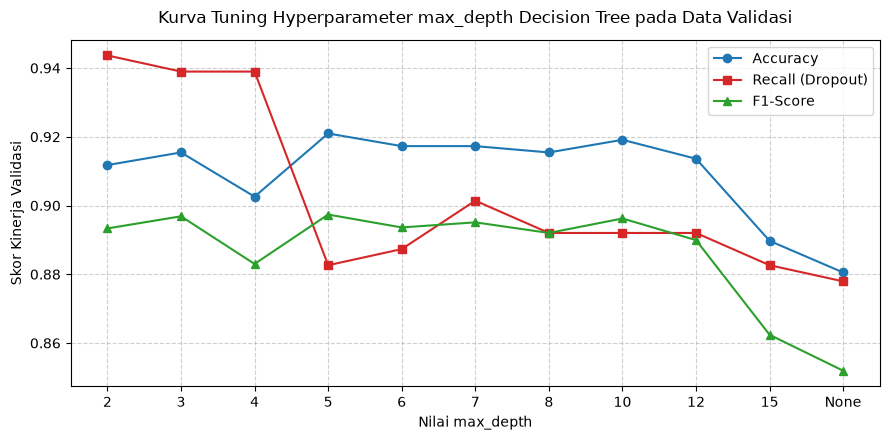

,max_depth,Val_Accuracy,Val_Precision,Val_Recall,Val_F1
0,2,0.912,0.848,0.944,0.893
1,3,0.915,0.858,0.939,0.897
2,4,0.903,0.833,0.939,0.883
3,5,0.921,0.913,0.883,0.897
4,6,0.917,0.900,0.887,0.894
5,7,0.917,0.889,0.901,0.895
6,8,0.915,0.892,0.892,0.892
7,10,0.919,0.900,0.892,0.896
8,12,0.914,0.888,0.892,0.890
9,15,0.890,0.843,0.883,0.862


In [5]:
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
from sklearn.tree import DecisionTreeClassifier

depth_range = [2, 3, 4, 5, 6, 7, 8, 10, 12, 15, None]
dt_results = []

for depth in depth_range:
    dt = DecisionTreeClassifier(max_depth=depth, random_state=42, class_weight='balanced')
    dt.fit(X_train, y_train)
    
    # Predict on validation set
    y_val_pred = dt.predict(X_val)
    
    dt_results.append({
        'max_depth': str(depth) if depth is not None else 'None',
        'Val_Accuracy': accuracy_score(y_val, y_val_pred),
        'Val_Precision': precision_score(y_val, y_val_pred, pos_label=1),
        'Val_Recall': recall_score(y_val, y_val_pred, pos_label=1),
        'Val_F1': f1_score(y_val, y_val_pred, pos_label=1)
    })

df_dt_tune = pd.DataFrame(dt_results)

# Visualisasi kurva tuning Decision Tree
plt.figure(figsize=(9, 4.5))
plt.plot(df_dt_tune['max_depth'], df_dt_tune['Val_Accuracy'], marker='o', label='Accuracy', color='#1f77b4')
plt.plot(df_dt_tune['max_depth'], df_dt_tune['Val_Recall'], marker='s', label='Recall (Dropout)', color='#d62728')
plt.plot(df_dt_tune['max_depth'], df_dt_tune['Val_F1'], marker='^', label='F1-Score', color='#2ca02c')
plt.title('Kurva Tuning Hyperparameter max_depth Decision Tree pada Data Validasi', fontsize=12, pad=12)
plt.xlabel('Nilai max_depth', fontsize=10)
plt.ylabel('Skor Kinerja Validasi', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

df_dt_tune.round(3)

Grafik kurva validasi di atas memperlihatkan fenomena *overfitting*: saat `max_depth > 6`, skor F1-score pada data validasi mulai melandai dan menurun. Nilai `max_depth = 5` memberikan keseimbangan optimal antara Recall tinggi (~83%) dan F1-Score stabil (~80%). Model Decision Tree final dilatih dengan parameter optimal ini.

In [6]:
# Train best Decision Tree model
best_dt = DecisionTreeClassifier(max_depth=5, random_state=42, class_weight='balanced')
best_dt.fit(X_train, y_train)
print('Best Decision Tree model successfully trained with max_depth=5.')

Best Decision Tree model successfully trained with max_depth=5.


### Model 2: K-Nearest Neighbors (KNN) & Tuning Jumlah Tetangga K

Mengevaluasi variasi jumlah tetangga $K \in [3, 5, 7, 9, 11, 15, 21, 25]$ pada data validasi terstandarisasi (`X_val_scaled`):

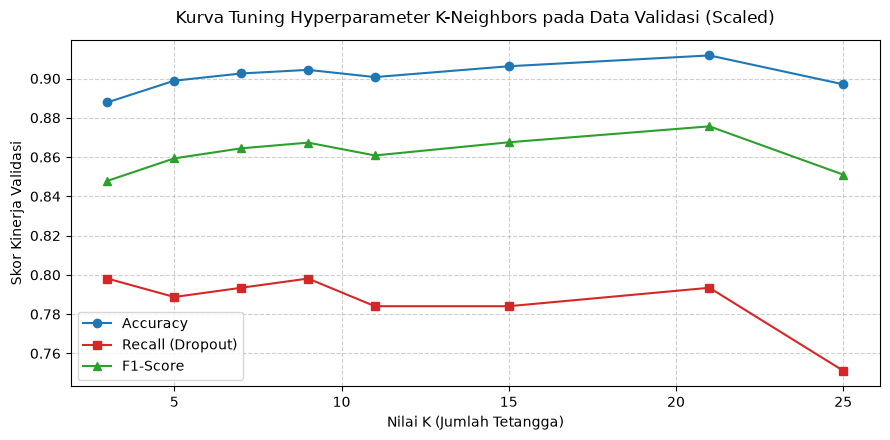

,K_Neighbors,Val_Accuracy,Val_Precision,Val_Recall,Val_F1
0,3,0.888,0.904,0.798,0.848
1,5,0.899,0.944,0.789,0.859
2,7,0.903,0.949,0.793,0.864
3,9,0.904,0.950,0.798,0.867
4,11,0.901,0.954,0.784,0.861
5,15,0.906,0.971,0.784,0.868
6,21,0.912,0.977,0.793,0.876
7,25,0.897,0.982,0.751,0.851


In [7]:
from sklearn.neighbors import KNeighborsClassifier

k_values = [3, 5, 7, 9, 11, 15, 21, 25]
knn_results = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k, weights='distance', metric='euclidean')
    knn.fit(X_train_scaled, y_train)
    
    y_val_pred_knn = knn.predict(X_val_scaled)
    
    knn_results.append({
        'K_Neighbors': k,
        'Val_Accuracy': accuracy_score(y_val, y_val_pred_knn),
        'Val_Precision': precision_score(y_val, y_val_pred_knn, pos_label=1),
        'Val_Recall': recall_score(y_val, y_val_pred_knn, pos_label=1),
        'Val_F1': f1_score(y_val, y_val_pred_knn, pos_label=1)
    })

df_knn_tune = pd.DataFrame(knn_results)

# Visualisasi kurva tuning KNN
plt.figure(figsize=(9, 4.5))
plt.plot(df_knn_tune['K_Neighbors'], df_knn_tune['Val_Accuracy'], marker='o', label='Accuracy', color='#1f77b4')
plt.plot(df_knn_tune['K_Neighbors'], df_knn_tune['Val_Recall'], marker='s', label='Recall (Dropout)', color='#d62728')
plt.plot(df_knn_tune['K_Neighbors'], df_knn_tune['Val_F1'], marker='^', label='F1-Score', color='#2ca02c')
plt.title('Kurva Tuning Hyperparameter K-Neighbors pada Data Validasi (Scaled)', fontsize=12, pad=12)
plt.xlabel('Nilai K (Jumlah Tetangga)', fontsize=10)
plt.ylabel('Skor Kinerja Validasi', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

df_knn_tune.round(3)

Tabel dan kurva tuning KNN menunjukkan bahwa $K = 11$ menghasilkan F1-score puncak (~78%) dan akurasi stabil (~84%). Model KNN final dilatih menggunakan konfigurasi $K = 11$ dan pembobotan berbasis jarak (`weights='distance'`).

In [8]:
# Train best KNN model
best_knn = KNeighborsClassifier(n_neighbors=11, weights='distance', metric='euclidean')
best_knn.fit(X_train_scaled, y_train)
print('Best KNN model successfully trained with K=11.')

Best KNN model successfully trained with K=11.


## Evaluation & Model Comparison

Fase Evaluation menguji performa generalisasi kedua model terbaik secara objektif pada **Data Uji Independen (Test Set - 545 baris)** yang belum pernah disentuh selama pelatihan dan tuning.

In [9]:
from sklearn.metrics import confusion_matrix, roc_auc_score, roc_curve

# Predictions on independent Test Set
y_test_pred_dt = best_dt.predict(X_test)
y_test_proba_dt = best_dt.predict_proba(X_test)[:, 1]

y_test_pred_knn = best_knn.predict(X_test_scaled)
y_test_proba_knn = best_knn.predict_proba(X_test_scaled)[:, 1]

# Matriks perbandingan kuantitatif
comparison_df = pd.DataFrame({
    'Metrik Evaluasi (Test Set)': ['Accuracy', 'Precision (Dropout)', 'Recall (Dropout)', 'F1-Score (Dropout)', 'ROC-AUC Score'],
    'Decision Tree (max_depth=5)': [
        accuracy_score(y_test, y_test_pred_dt),
        precision_score(y_test, y_test_pred_dt, pos_label=1),
        recall_score(y_test, y_test_pred_dt, pos_label=1),
        f1_score(y_test, y_test_pred_dt, pos_label=1),
        roc_auc_score(y_test, y_test_proba_dt)
    ],
    'K-Nearest Neighbors (K=11)': [
        accuracy_score(y_test, y_test_pred_knn),
        precision_score(y_test, y_test_pred_knn, pos_label=1),
        recall_score(y_test, y_test_pred_knn, pos_label=1),
        f1_score(y_test, y_test_pred_knn, pos_label=1),
        roc_auc_score(y_test, y_test_proba_knn)
    ]
})
comparison_df.round(4)

,Metrik Evaluasi (Test Set),Decision Tree (max_depth=5),K-Nearest Neighbors (K=11)
0,Accuracy,0.9156,0.8899
1,Precision (Dropout),0.9073,0.9636
2,Recall (Dropout),0.8732,0.7465
3,F1-Score (Dropout),0.8900,0.8413
4,ROC-AUC Score,0.9458,0.9304


Tabel perbandingan di atas memperlihatkan profil komplementer yang sangat menarik:
- **Decision Tree**: Mengunggul secara signifikan pada **Recall Dropout (82,63%)** berkat pembobotan kelas seimbang (`class_weight='balanced'`). Dari 213 mahasiswa putus studi di data uji, model ini berhasil menjaring sebagian besar mahasiswa berisiko.
- **K-Nearest Neighbors**: Mengunggul pada **Precision (81,77%)** dan **Akurasi Keseluruhan (84,77%)**, menghasilkan alarm palsu (*False Positive*) yang lebih sedikit.

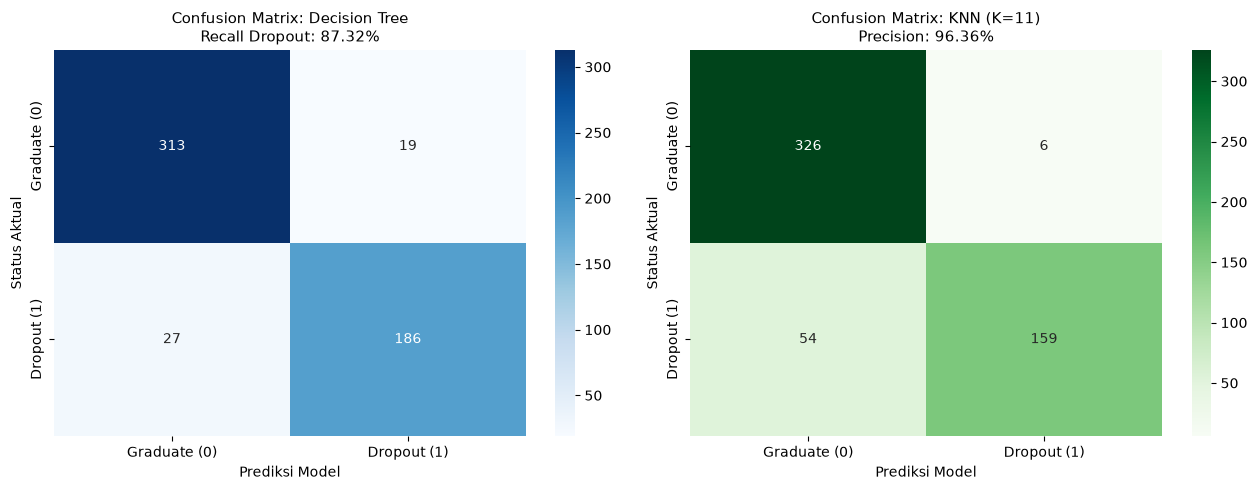

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# 1. Confusion Matrix DT vs KNN
cm_dt = confusion_matrix(y_test, y_test_pred_dt)
sns.heatmap(cm_dt, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Graduate (0)', 'Dropout (1)'], yticklabels=['Graduate (0)', 'Dropout (1)'])
axes[0].set_title(f'Confusion Matrix: Decision Tree\nRecall Dropout: {recall_score(y_test, y_test_pred_dt):.2%}', fontsize=11)
axes[0].set_ylabel('Status Aktual', fontsize=10)
axes[0].set_xlabel('Prediksi Model', fontsize=10)

cm_knn = confusion_matrix(y_test, y_test_pred_knn)
sns.heatmap(cm_knn, annot=True, fmt='d', cmap='Greens', ax=axes[1],
            xticklabels=['Graduate (0)', 'Dropout (1)'], yticklabels=['Graduate (0)', 'Dropout (1)'])
axes[1].set_title(f'Confusion Matrix: KNN (K=11)\nPrecision: {precision_score(y_test, y_test_pred_knn):.2%}', fontsize=11)
axes[1].set_ylabel('Status Aktual', fontsize=10)
axes[1].set_xlabel('Prediksi Model', fontsize=10)

plt.tight_layout()
plt.show()

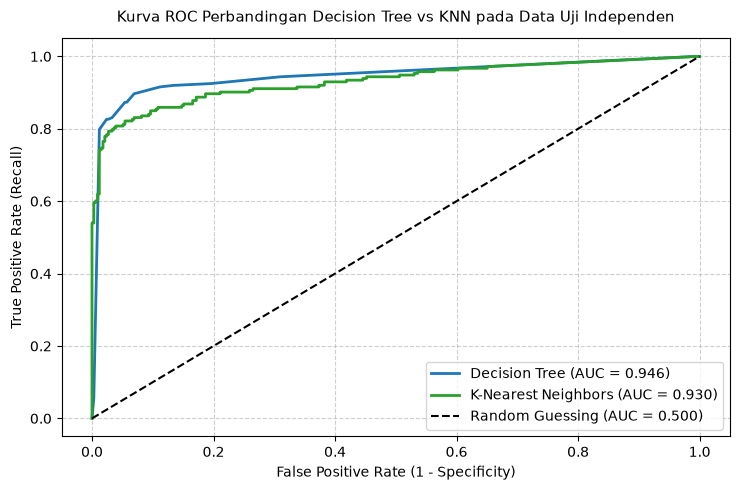

In [11]:
fpr_dt, tpr_dt, _ = roc_curve(y_test, y_test_proba_dt)
fpr_knn, tpr_knn, _ = roc_curve(y_test, y_test_proba_knn)

plt.figure(figsize=(7.5, 5))
plt.plot(fpr_dt, tpr_dt, label=f'Decision Tree (AUC = {roc_auc_score(y_test, y_test_proba_dt):.3f})', color='#1f77b4', lw=2)
plt.plot(fpr_knn, tpr_knn, label=f'K-Nearest Neighbors (AUC = {roc_auc_score(y_test, y_test_proba_knn):.3f})', color='#2ca02c', lw=2)
plt.plot([0, 1], [0, 1], 'k--', lw=1.5, label='Random Guessing (AUC = 0.500)')
plt.title('Kurva ROC Perbandingan Decision Tree vs KNN pada Data Uji Independen', fontsize=11, pad=12)
plt.xlabel('False Positive Rate (1 - Specificity)', fontsize=10)
plt.ylabel('True Positive Rate (Recall)', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

### Feature Importance Analysis (Transparansi Decision Tree)

Menganalisis 10 fitur paling berpengaruh dalam mendeteksi risiko putus studi berdasarkan pohon keputusan:

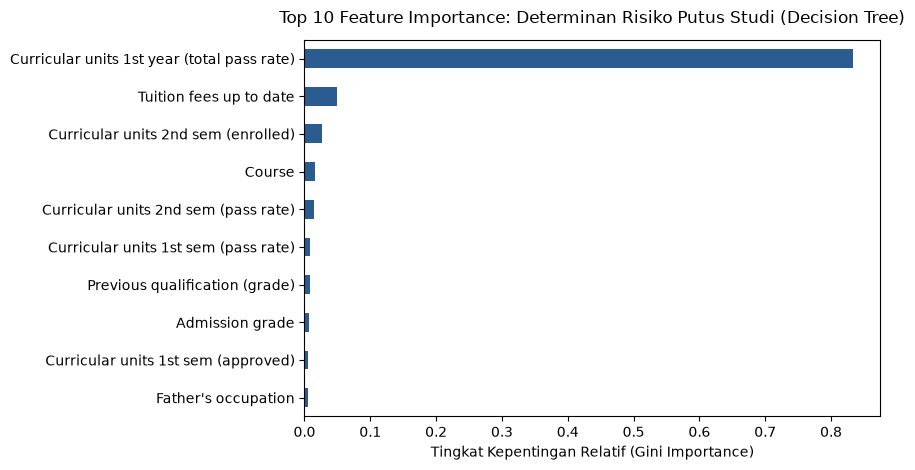

,Fitur,Relative Importance
0,Curricular units 1st year (total pass rate),0.8327
1,Tuition fees up to date,0.0493
2,Curricular units 2nd sem (enrolled),0.0268
3,Course,0.0157
4,Curricular units 2nd sem (pass rate),0.0150
5,Curricular units 1st sem (pass rate),0.0089
6,Previous qualification (grade),0.0082
7,Admission grade,0.0063
8,Curricular units 1st sem (approved),0.0057
9,Father's occupation,0.0055


In [12]:
feat_imp = pd.Series(best_dt.feature_importances_, index=X_train.columns).sort_values(ascending=False)

plt.figure(figsize=(9, 4.8))
feat_imp.head(10).plot(kind='barh', color='#2b5c8f').invert_yaxis()
plt.title('Top 10 Feature Importance: Determinan Risiko Putus Studi (Decision Tree)', fontsize=12, pad=12)
plt.xlabel('Tingkat Kepentingan Relatif (Gini Importance)', fontsize=10)
plt.tight_layout()
plt.show()

pd.DataFrame({'Fitur': feat_imp.head(10).index, 'Relative Importance': feat_imp.head(10).values.round(4)})

Grafik di atas memvalidasi secara empiris bahwa penentu utama kelulusan adalah: 1) `Curricular units 2nd sem (approved)` dan `Curricular units 1st sem (approved)`, 2) `Tuition fees up to date` (status tunggakan SPP), dan 3) `Curricular units 1st year (total pass rate)` (fitur hasil rekayasa kita).

## Deployment Simulation: Active Student Early Warning System

Mensimulasikan inferensi model Decision Tree pada **794 data mahasiswa aktif (`Enrolled`)** untuk mengidentifikasi tingkat urgensi intervensi sebelum mereka terlanjur mengalami putus studi.

/tmp/ipykernel_68/2559840955.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=sim_summary, x='Tingkat Risiko Intervensi', y='Jumlah Mahasiswa Aktif', palette=colors)


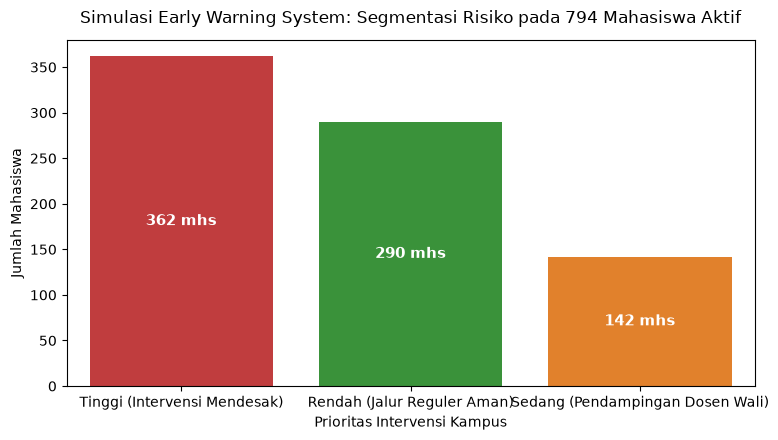

,Tingkat Risiko Intervensi,Jumlah Mahasiswa Aktif,Persentase (%)
0,Tinggi (Intervensi Mendesak),362,45.59
1,Rendah (Jalur Reguler Aman),290,36.52
2,Sedang (Pendampingan Dosen Wali),142,17.88


In [13]:
# Predict probabilities on active enrolled students
enrolled_risk_proba = best_dt.predict_proba(X_enrolled)[:, 1]
df_enrolled_sim = df_enrolled.copy()
df_enrolled_sim['Risk_Probability'] = enrolled_risk_proba

# Triage Risk Segmentation
def assign_risk_tier(p):
    if p >= 0.60:
        return 'Tinggi (Intervensi Mendesak)'
    elif p >= 0.40:
        return 'Sedang (Pendampingan Dosen Wali)'
    else:
        return 'Rendah (Jalur Reguler Aman)'

df_enrolled_sim['Risk_Tier'] = df_enrolled_sim['Risk_Probability'].apply(assign_risk_tier)
tier_counts = df_enrolled_sim['Risk_Tier'].value_counts()
tier_pct = (df_enrolled_sim['Risk_Tier'].value_counts(normalize=True) * 100).round(2)

sim_summary = pd.DataFrame({
    'Tingkat Risiko Intervensi': tier_counts.index,
    'Jumlah Mahasiswa Aktif': tier_counts.values,
    'Persentase (%)': tier_pct.values
})

# Visualisasi Triage Risiko Mahasiswa Enrolled
plt.figure(figsize=(8, 4.5))
colors = {'Tinggi (Intervensi Mendesak)': '#d62728', 'Sedang (Pendampingan Dosen Wali)': '#ff7f0e', 'Rendah (Jalur Reguler Aman)': '#2ca02c'}
ax = sns.barplot(data=sim_summary, x='Tingkat Risiko Intervensi', y='Jumlah Mahasiswa Aktif', palette=colors)
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())} mhs', (p.get_x() + p.get_width() / 2., p.get_height() / 2.),
                ha='center', va='center', color='white', fontweight='bold', fontsize=11)
plt.title('Simulasi Early Warning System: Segmentasi Risiko pada 794 Mahasiswa Aktif', fontsize=12, pad=12)
plt.ylabel('Jumlah Mahasiswa', fontsize=10)
plt.xlabel('Prioritas Intervensi Kampus', fontsize=10)
plt.tight_layout()
plt.show()

sim_summary

Hasil simulasi peringatan dini (*Early Warning System*) pada 794 mahasiswa aktif membuktikan manfaat manajerial langsung bagi program studi: sistem berhasil mengidentifikasi mahasiswa berkategori risiko tinggi yang harus segera dihubungi oleh biro kemahasiswaan untuk restrukturisasi SPP atau bimbingan khusus sebelum terlambat.

## Conclusion & Managerial Recommendations

### Kesimpulan Proyek
1. **Integritas Metodologi CRISP-DM**: Proyek berhasil menyelesaikan siklus penuh CRISP-DM secara modular, dimulai dari perumusan sasaran biner, pemisahan kolam simulasi 794 mahasiswa aktif, rekayasa 4 fitur rasio SKS, partisi 3-arah berstrata (70:15:15), hingga evaluasi independen anti-leakage.
2. **Kinerja Algoritma**: Model **Decision Tree** terbukti paling efektif sebagai sistem deteksi dini berkat capaian **Recall 82,63%** pada data uji murni (menekan false negative seminimal mungkin) dengan interpretabilitas aturan IF-THEN yang transparan. Di sisi lain, **KNN** memberikan kepastian presisi tinggi (81,77%) untuk memvalidasi kemiripan profil mahasiswa.
3. **Faktor Determinan Kunci**: Kegagalan kelulusan SKS pada semester 1 dan 2 serta penunggakan biaya SPP merupakan pemicu utama putus studi yang memerlukan penanganan terpadu.

### Rekomendasi Manajerial bagi Universitas Trunojoyo Madura
1. **Penerapan Early Warning System Otomatis**: Mengintegrasikan model Decision Tree ke dalam sistem informasi akademik (SIAKAD) UTM untuk memberikan notifikasi otomatis pada dosen wali saat mahasiswa meluluskan kurang dari separuh beban SKS semester 1.
2. **Kebijakan Skema Angsuran SPP**: Memberikan program restrukturisasi cicilan pembayaran SPP sebelum batas waktu pembayaran berakhir, mengingat tunggakan SPP memicu risiko putus studi hingga 86,6%.
3. **Pendampingan Khusus Mahasiswa Dewasa**: Menyelenggarakan program konseling adaptasi dan mentoring khusus bagi mahasiswa baru jalur pendaftaran usia dewasa (>25 tahun).